# Decentralized Bayesian Lasso Regression with Regional Data (California Housing)

Section 5.4 of the paper. 20,433 complete districts; response $\log$(median house value) (centered); ten standardized features.
The agents are $N$ **geographic regions** from $k$-means on the coordinates, so the data of the agents are not identically distributed.
Gaussian likelihood with plug-in noise variance from the OLS residuals, and a $\mathcal N(0,\tau^2 I)$ prior restricted to the
$\ell_1$-ball $\mathcal K=\{\|\beta\|_1\le s\}$ with $s=0.8\,\|\beta_{\rm OLS}\|_1$ (a Bayesian Lasso).

In [1]:
import sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "experiments" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
from src import (NETWORK_NAMES, mixing_matrix, de_psgld, psgld, w2_empirical,
                 problems, apply_style, COLORS)

apply_style()
FIG_DIR = ROOT / "figure"
FIG_DIR.mkdir(exist_ok=True)
%matplotlib inline

## Parameters

In [2]:
# problem
N      = 20         # number of regions = agents
BATCH  = 32
TAU2   = 100.0
SHRINK = 0.8        # s = SHRINK * ||beta_OLS||_1
DATA_SEED = 0       # k-means and train/test split

# sampler
GAMMA    = 1e-6
ETA_FRAC = 0.6
N_ITER   = 3000   # the largest region has a large smoothness constant, so eta is small
RECORD_EVERY = 200
M        = 200
SEED     = 1
NETWORKS = ["full", "ring", "star"]
AGENTS_TO_SHOW = [0, 4, 9]   # agent 1 = largest region (hub of the star), agent 10 = smallest

RMSE_YLIM = (0.30, 0.46)
SAVE_FIGS = True

## Problem and stepsize

In [3]:
prob = problems.housing_lasso(N=N, batch=BATCH, tau2=TAU2, shrink=SHRINK, seed=DATA_SEED)
eta = ETA_FRAC * prob.eta_max(GAMMA)
eta_c = eta / N
beta_K = prob.constrained_ls(prob.Xtr, prob.ytr)                       # centralized lasso solution
local = [prob.constrained_ls(prob.Xloc[i], prob.yloc[i]) for i in range(N)]
local_rmse = np.array([prob.rmse(b) for b in local])
print(f"n_i = {prob.n_i.tolist()},  d = {prob.d},  sigma^2 = {prob.sig2:.4f}")
print(f"||beta_OLS||_1 = {np.abs(prob.beta_ols).sum():.3f},  s = {prob.s:.3f}")
print(f"test RMSE: OLS = {prob.rmse(prob.beta_ols):.4f},  lasso = {prob.rmse(beta_K):.4f},  "
      f"local data only = {local_rmse.round(3)} (avg {local_rmse.mean():.3f})")
print(f"L = {prob.L:.1f},  eta = {eta:.3e},  eta_central = {eta_c:.3e}")

n_i = [2836, 2103, 1801, 1581, 1281, 1104, 835, 784, 738, 690, 389, 370, 346, 340, 316, 212, 183, 160, 144, 133],  d = 10,  sigma^2 = 0.1043
||beta_OLS||_1 = 1.509,  s = 1.207
test RMSE: OLS = 0.3146,  lasso = 0.3158,  local data only = [0.686 0.333 0.381 0.492 0.543 0.425 0.459 0.381 0.397 0.389 0.347 0.39
 0.38  0.771 0.698 0.504 0.604 0.408 0.39  0.445] (avg 0.471)
L = 189755.0,  eta = 2.071e-06,  eta_central = 1.035e-07


## Run

In [4]:
x0 = np.zeros((M, N, prob.d))
def record(B, k):
    Bm = B.mean(1)
    return ([prob.rmse(B[:, i]) for i in AGENTS_TO_SHOW], prob.rmse(Bm),
            np.mean(np.linalg.norm(B - Bm[:, None], axis=-1)))

res = {}
for kind in NETWORKS:
    W, rho, _ = mixing_matrix(kind, N)
    BT, out = de_psgld(x0, W, prob.stoch_grad, prob.proj, eta, GAMMA, N_ITER, seed=SEED,
                       record=record, record_every=RECORD_EVERY, progress=NETWORK_NAMES[kind])
    res[kind] = dict(rho=rho, agents=np.array([o[0] for o in out]), mean=np.array([o[1] for o in out]),
                     cons=np.array([o[2] for o in out]), final=BT)

BC, out_c = psgld(np.zeros((M, prob.d)), prob.stoch_grad_central, prob.proj, eta_c, GAMMA, N_ITER,
                  seed=SEED, record=lambda B, k: prob.rmse(B), record_every=RECORD_EVERY, progress="PSGLD")
rmse_central = np.array(out_c)
iters = np.arange(0, N_ITER + 1, RECORD_EVERY)

  Fully Connected: 3000/3000 iterations (31s)
  Circular: 3000/3000 iterations (34s)
  Star: 3000/3000 iterations (39s)
  PSGLD: 3000/3000 iterations (36s)


## Regions and test RMSE vs iterations

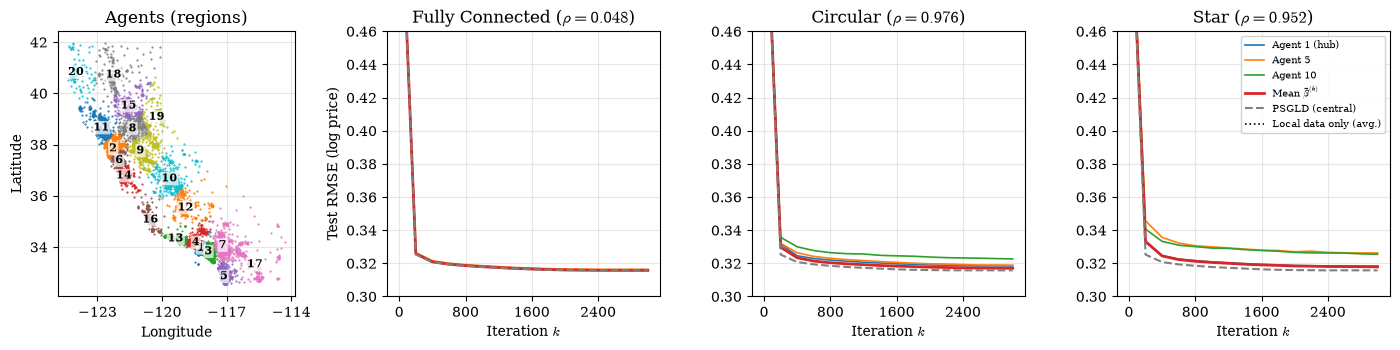

In [5]:
fig = plt.figure(figsize=(3.6 + 3.5 * len(NETWORKS), 3.6))
gs = fig.add_gridspec(1, len(NETWORKS) + 1, width_ratios=[1] + [1.15] * len(NETWORKS))
ax0 = fig.add_subplot(gs[0]); cmap = plt.get_cmap("tab10")
lon, lat = prob.coords["longitude"].values, prob.coords["latitude"].values
for i in range(N):
    sel = prob.agent == i
    ax0.scatter(lon[sel], lat[sel], s=0.3, color=cmap(i % 10), rasterized=True)
    ax0.text(lon[sel].mean(), lat[sel].mean(), str(i + 1), fontsize=8, ha="center", va="center", weight="bold",
             bbox=dict(boxstyle="round,pad=0.1", fc="w", alpha=0.7, lw=0))
ax0.set_xlabel("Longitude"); ax0.set_ylabel("Latitude"); ax0.set_title("Agents (regions)")
ax0.xaxis.set_major_locator(plt.MaxNLocator(4))
axes = [fig.add_subplot(gs[j + 1]) for j in range(len(NETWORKS))]
for ax, kind in zip(axes, NETWORKS):
    r = res[kind]
    for q, i in enumerate(AGENTS_TO_SHOW):
        lab = f"Agent {i+1}" + (" (hub)" if kind == "star" and i == 0 else "")
        ax.plot(iters, r["agents"][:, q], color=COLORS[q], lw=1.2, label=lab)
    ax.plot(iters, r["mean"], color=COLORS[3], lw=2, label=r"Mean $\bar\beta^{(k)}$")
    ax.plot(iters, rmse_central, color="gray", ls="--", lw=1.5, label="PSGLD (central)")
    ax.axhline(local_rmse.mean(), color="k", ls=":", lw=1.2, label="Local data only (avg.)")
    ax.set_ylim(*RMSE_YLIM); ax.set_xlabel("Iteration $k$"); ax.xaxis.set_major_locator(plt.MaxNLocator(5))
    ax.set_title(f"{NETWORK_NAMES[kind]} ($\\rho={r['rho']:.3f}$)")
axes[0].set_ylabel("Test RMSE (log price)"); axes[-1].legend(fontsize=7)
fig.tight_layout()
if SAVE_FIGS:
    for ext in ("pdf", "png"):
        fig.savefig(FIG_DIR / f"exp4_housing_rmse.{ext}", dpi=200, bbox_inches="tight")

## Posterior of the coefficients

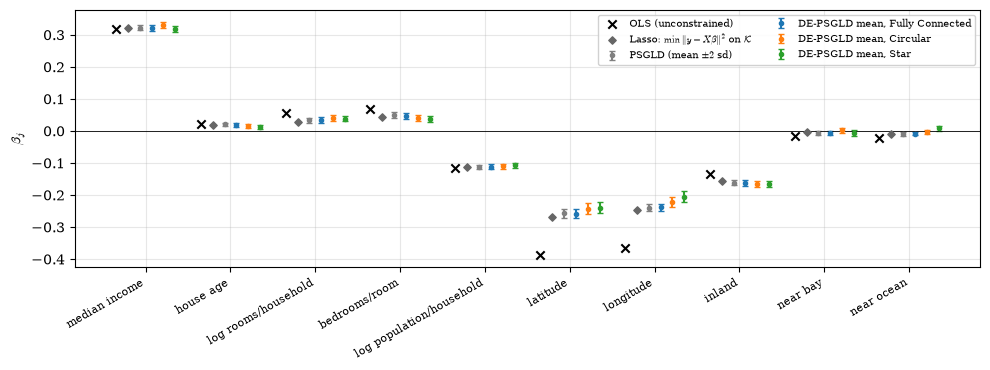

In [6]:
fig, ax = plt.subplots(figsize=(10, 3.8))
xs = np.arange(prob.d); w = 0.14
ax.scatter(xs - 2.5 * w, prob.beta_ols, marker="x", color="k", zorder=3, label="OLS (unconstrained)")
ax.scatter(xs - 1.5 * w, beta_K, marker="D", s=14, color="0.4", zorder=3, label=r"Lasso: $\min\|y-X\beta\|^2$ on $\mathcal{K}$")
def err(B, off, col, lab):
    ax.errorbar(xs + off, B.mean(0), yerr=2 * B.std(0), fmt="o", ms=3, color=col, capsize=2, label=lab)
err(BC, -0.5 * w, "gray", r"PSGLD (mean $\pm 2$ sd)")
for j, kind in enumerate(NETWORKS):
    err(res[kind]["final"].mean(1), (0.5 + j) * w, COLORS[j], f"DE-PSGLD mean, {NETWORK_NAMES[kind]}")
ax.axhline(0, color="k", lw=0.6)
ax.set_xticks(xs); ax.set_xticklabels(prob.names, rotation=30, ha="right", fontsize=8)
ax.set_ylabel(r"$\beta_j$"); ax.legend(fontsize=7, ncol=2)
fig.tight_layout()
if SAVE_FIGS:
    for ext in ("pdf", "png"):
        fig.savefig(FIG_DIR / f"exp4_housing_coef.{ext}", dpi=200, bbox_inches="tight")

## Summary

In [7]:
rows = []
for k in NETWORKS:
    r = res[k]
    rows.append(dict(network=NETWORK_NAMES[k], rho=r["rho"], rmse_mean=r["mean"][-1],
                     **{f"rmse_agent{i+1}": v for i, v in zip(AGENTS_TO_SHOW, r["agents"][-1])},
                     consensus=r["cons"][-1]))
rows += [dict(network="PSGLD (central)", rmse_mean=rmse_central[-1]),
         dict(network="Lasso (central)", rmse_mean=prob.rmse(beta_K)),
         dict(network="OLS (central)", rmse_mean=prob.rmse(prob.beta_ols)),
         dict(network="Local data only (avg.)", rmse_mean=local_rmse.mean())]
pd.DataFrame(rows).round(4)

,network,rho,rmse_mean,rmse_agent1,rmse_agent5,rmse_agent10,consensus
0,Fully Connected,0.0476,0.3158,0.3161,0.3164,0.3157,0.0083
1,Circular,0.9755,0.3170,0.3184,0.3189,0.3227,0.0366
2,Star,0.9524,0.3179,0.3183,0.3263,0.3255,0.0431
3,PSGLD (central),NaN,0.3158,NaN,NaN,NaN,NaN
4,Lasso (central),NaN,0.3158,NaN,NaN,NaN,NaN
5,OLS (central),NaN,0.3146,NaN,NaN,NaN,NaN
6,Local data only (avg.),NaN,0.4711,NaN,NaN,NaN,NaN
